# Ames Housing Price Prediction

This notebook is a full regression workflow on the Ames Housing dataset.

I will:
- inspect the data and the target (`SalePrice`)
- do manual EDA and automated EDA
- clean and encode features inside sklearn pipelines
- tune SVR and Ridge
- compare MAE, MSE, RMSE, and R2 on train / validation / test


## 1. Setup and dataset loading

I keep a fixed random seed so the split and the tuning results can be reproduced.


In [1]:
# basic libraries
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn pieces I need for a leakage-safe pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

# load the csv. pandas already treats the text "NA" as missing
df = pd.read_csv('AmesHousing.csv')

# make column names easier to type
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('/', '_', regex=False)
)

# Order and PID are just IDs, they should not be used as predictors
df = df.drop(columns=['order', 'pid'], errors='ignore')

target = 'saleprice'
print('Data loaded. Rows and columns:', df.shape)


Data loaded. Rows and columns: (2930, 80)


## 2. Dataset understanding

Target variable: **SalePrice** (sale price of the house in USD).

I dropped `Order` and `PID` because they are identifiers, not house features.
The remaining columns describe size, quality, location, and sale details.


In [2]:
# first look at the table
print('Shape:', df.shape)
print('Duplicate rows:', int(df.duplicated().sum()))
print()
print('Data types:')
print(df.dtypes.value_counts())
df.head()


Shape: (2930, 80)
Duplicate rows: 0

Data types:
object     43
int64      26
float64    11
Name: count, dtype: int64


,ms_subclass,ms_zoning,lot_frontage,lot_area,street,alley,lot_shape,land_contour,utilities,lot_config,...,pool_area,pool_qc,fence,misc_feature,misc_val,mo_sold,yr_sold,sale_type,sale_condition,saleprice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
# missing values, sorted so the worst columns show first
missing = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2)
}).sort_values('missing', ascending=False)

print('Columns with missing values:', int((missing['missing'] > 0).sum()))
missing.head(20)


Columns with missing values: 27


,dtype,missing,missing_%
pool_qc,object,2917,99.56
misc_feature,object,2824,96.38
alley,object,2732,93.24
fence,object,2358,80.48
mas_vnr_type,object,1775,60.58
fireplace_qu,object,1422,48.53
lot_frontage,float64,490,16.72
garage_cond,object,159,5.43
garage_yr_blt,float64,159,5.43
garage_finish,object,159,5.43


In [4]:
# target summary
print('Target column:', target)
df[target].describe().to_frame('saleprice')


Target column: saleprice


,saleprice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


In [5]:
# quick feature counts before I split them into numeric / ordinal / nominal
print('Numeric columns including the target:', df.select_dtypes(include=np.number).shape[1])
print('Categorical columns:', df.select_dtypes(exclude=np.number).shape[1])


Numeric columns including the target: 37
Categorical columns: 43


**What I noticed here**
- The table has 2930 houses and 80 columns after dropping IDs.
- There are no duplicate rows, so I do not drop any records for duplication.
- A lot of missing values are not really "unknown". In Ames, `NA` often means the house has no pool, no alley, no fence, or no garage.
- `SalePrice` ranges from about 12.8k to 755k, with a mean around 181k. That spread already suggests outliers and a right-skewed target.


## 3. Manual EDA

I expect `SalePrice` to be right-skewed (many normal houses, a few very expensive ones).
If that is true, I will train on `log1p(SalePrice)` and convert predictions back to dollars before scoring.


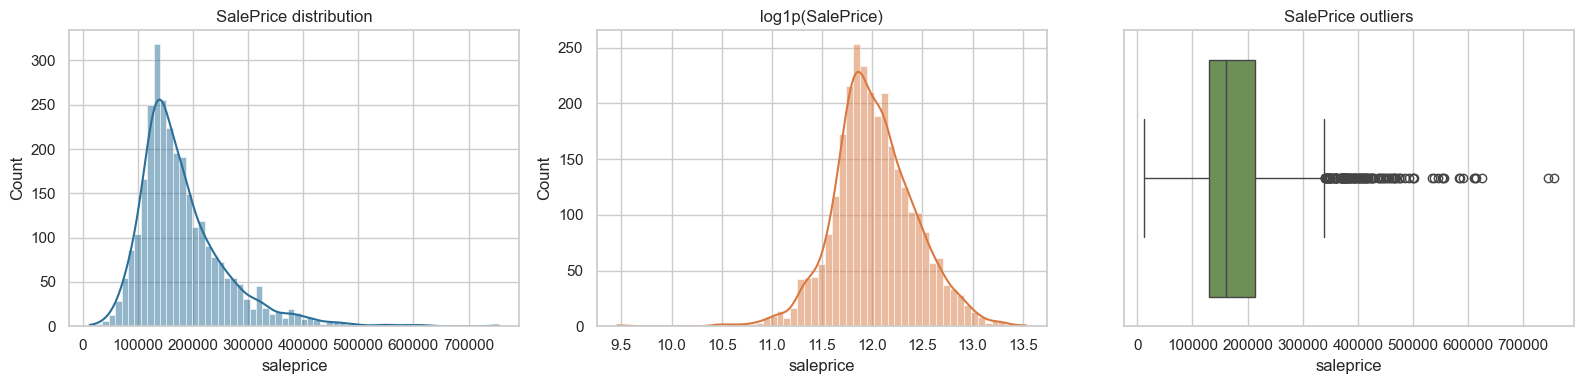

Skew of SalePrice: 1.744
Skew after log1p: -0.015


In [6]:
# SalePrice shape: raw, log, and outliers
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df[target], kde=True, ax=axes[0], color='#2a6f97')
axes[0].set_title('SalePrice distribution')

sns.histplot(np.log1p(df[target]), kde=True, ax=axes[1], color='#d97941')
axes[1].set_title('log1p(SalePrice)')

sns.boxplot(x=df[target], ax=axes[2], color='#6a994e')
axes[2].set_title('SalePrice outliers')

plt.tight_layout()
plt.show()

print('Skew of SalePrice:', round(df[target].skew(), 3))
print('Skew after log1p:', round(np.log1p(df[target]).skew(), 3))


In [7]:
# numeric correlation with price
numeric_corr = df.select_dtypes(include=np.number).corr()[target].sort_values(ascending=False)
print('Strongest numeric relations with SalePrice:')
display(numeric_corr.head(12).to_frame('corr_with_saleprice'))

print()
print('Weakest numeric relations with SalePrice:')
display(numeric_corr.tail(8).to_frame('corr_with_saleprice'))


Strongest numeric relations with SalePrice:


,corr_with_saleprice
saleprice,1.000000
overall_qual,0.799262
gr_liv_area,0.706780
garage_cars,0.647877
garage_area,0.640401
total_bsmt_sf,0.632280
1st_flr_sf,0.621676
year_built,0.558426
full_bath,0.545604
year_remod_add,0.532974



Weakest numeric relations with SalePrice:


,corr_with_saleprice
misc_val,-0.015691
yr_sold,-0.030569
bsmt_half_bath,-0.035835
low_qual_fin_sf,-0.037660
ms_subclass,-0.085092
overall_cond,-0.101697
kitchen_abvgr,-0.119814
enclosed_porch,-0.128787


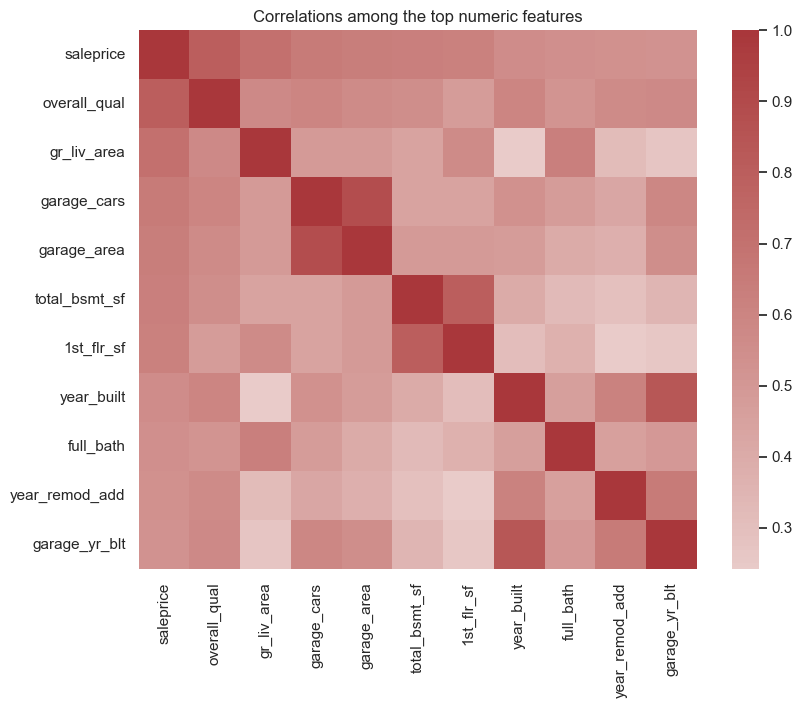

In [8]:
# heatmap for the features most related to price
top_cols = numeric_corr.abs().sort_values(ascending=False).head(11).index
plt.figure(figsize=(9, 7))
sns.heatmap(df[top_cols].corr(), cmap='vlag', center=0, annot=False)
plt.title('Correlations among the top numeric features')
plt.show()


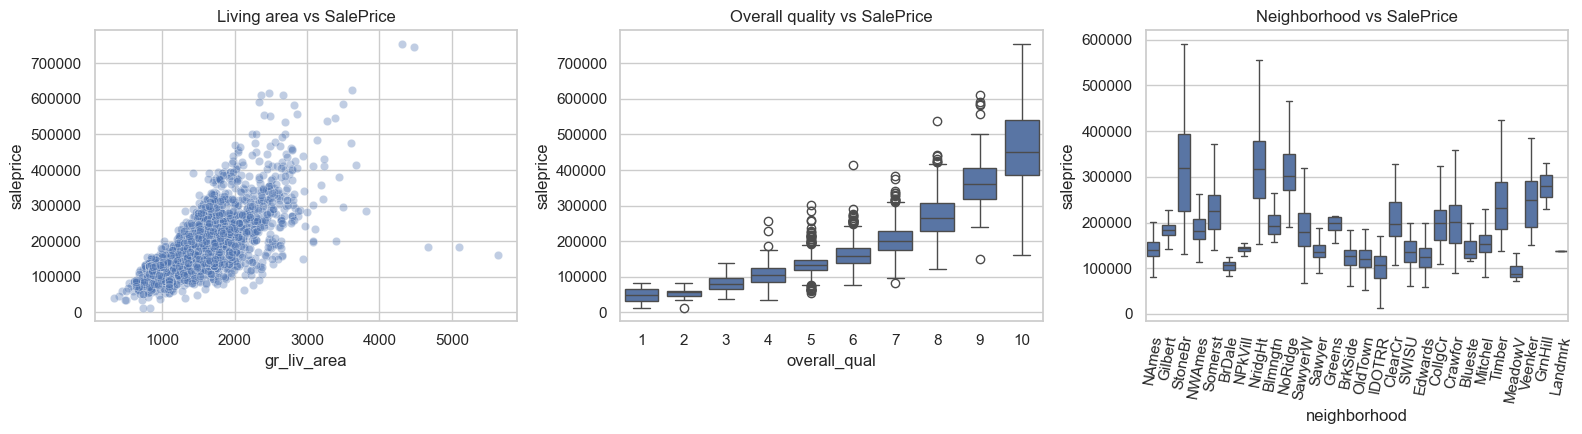

In [9]:
# relationships I care about as a buyer: size, quality, location
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(data=df, x='gr_liv_area', y=target, alpha=0.35, ax=axes[0])
axes[0].set_title('Living area vs SalePrice')

sns.boxplot(data=df, x='overall_qual', y=target, ax=axes[1])
axes[1].set_title('Overall quality vs SalePrice')

sns.boxplot(data=df, x='neighborhood', y=target, ax=axes[2], showfliers=False)
axes[2].tick_params(axis='x', rotation=80)
axes[2].set_title('Neighborhood vs SalePrice')

plt.tight_layout()
plt.show()


**Manual EDA notes**
- SalePrice is right-skewed. The log version looks much closer to normal, so a log target is a good idea.
- There are expensive outliers. I will keep them for now because they are real high-end houses, not data entry errors I can prove.
- `overall_qual` and `gr_liv_area` move with price in a clear way. Those two should matter in any good model.
- Neighborhood also matters. Location is not a number, so it needs categorical encoding.
- Some numeric features are correlated with each other (area features, garage cars vs garage area). That is one reason I prefer Ridge over plain Linear Regression later.
- Missing pool/garage/basement values are mostly "the house does not have this", so the model should see a `None` level, not a random fill.


## 4. Automated EDA (ydata-profiling)

The profiling report checks every column in a systematic way: missingness, distributions, correlations, and warnings.
I use `minimal=True` so the HTML file is lighter.


In [10]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    df,
    title='Ames Housing Automated EDA',
    explorative=True,
    minimal=True
)
profile.to_file('ames_housing_profile.html')
print('Saved ames_housing_profile.html')


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


  0%|          | 0/80 [00:00<?, ?it/s]


 72%|███████▎  | 58/80 [00:00<00:00, 533.20it/s]


100%|██████████| 80/80 [00:00<00:00, 568.60it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Saved ames_housing_profile.html


**Manual EDA vs automated EDA**
- Manual EDA helped me understand the *story*: quality, size, and neighborhood drive price, and SalePrice needs a log.
- Automated EDA is better at the *checklist*: it flags high missingness, rare categories, and pairwise correlations I might skip by hand.
- I still make modeling choices from the manual plots. The HTML report is the backup audit, not a replacement for looking at the data.


## 5. Preprocessing plan

I will do the actual transformations **inside sklearn pipelines**, fitted on the training fold only.

Decisions:
- **Missing values**
  - For features where `NA` means "this house does not have that item" (alley, basement, garage, pool, fence, fireplace, masonry), I fill with `None`.
  - Remaining numeric missing values: median.
  - Remaining categorical missing values: most frequent.
- **Duplicates**: none, so nothing to drop.
- **MS SubClass** looks numeric but it is a dwelling *type*, so I treat it as nominal.
- **Nominal categoricals**: One-Hot Encoding.
- **Ordinal categoricals**: Ordinal Encoding with a fixed quality order (`Po < Fa < TA < Gd < Ex`). `None` is the lowest level.
- **Numeric scaling**: `StandardScaler`. SVR uses distances / kernel similarity, so different units (sqft vs years vs counts) would dominate if I skip scaling. Ridge also benefits from scaling with regularization.
- **Target transform**: `log1p(SalePrice)` for training. Metrics are computed after `expm1` so they stay in dollars.
- **Simple feature engineering** (row-wise, no leakage): house age, remodel age, and total square footage.


In [11]:
# MS SubClass is a category stored as a number
df['ms_subclass'] = df['ms_subclass'].astype(str)

# simple extra features. each row only uses its own values
df['house_age'] = df['yr_sold'] - df['year_built']
df['remod_age'] = df['yr_sold'] - df['year_remod_add']
df['total_sf'] = df['total_bsmt_sf'].fillna(0) + df['1st_flr_sf'] + df['2nd_flr_sf']


In [12]:
# ordered quality / condition columns
# None is included because "no basement / no garage / no pool" is worse than Poor
ordinal_orders = {
    'exter_qual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'exter_cond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_qual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_cond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'heating_qc': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'kitchen_qual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'fireplace_qu': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'garage_qual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'garage_cond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'pool_qc': ['None', 'Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_exposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'bsmtfin_type_1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'bsmtfin_type_2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'functional': ['None', 'Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'garage_finish': ['None', 'Unf', 'RFn', 'Fin'],
    'paved_drive': ['N', 'P', 'Y'],
    'lot_shape': ['IR3', 'IR2', 'IR1', 'Reg'],
    'land_slope': ['Sev', 'Mod', 'Gtl'],
    'utilities': ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
}

# these columns use NA to mean "feature not present"

ordinal_features = [c for c in ordinal_orders if c in df.columns]
categorical_features = df.drop(columns=target).select_dtypes(exclude=np.number).columns.tolist()
nominal_features = [c for c in categorical_features if c not in ordinal_features]
numeric_features = df.drop(columns=target).select_dtypes(include=np.number).columns.tolist()

print('Numeric features:', len(numeric_features))
print('Nominal features:', len(nominal_features))
print('Ordinal features:', len(ordinal_features))
print()
print('Nominal:', nominal_features)
print()
print('Ordinal:', ordinal_features)


Numeric features: 38
Nominal features: 25
Ordinal features: 19

Nominal: ['ms_subclass', 'ms_zoning', 'street', 'alley', 'land_contour', 'lot_config', 'neighborhood', 'condition_1', 'condition_2', 'bldg_type', 'house_style', 'roof_style', 'roof_matl', 'exterior_1st', 'exterior_2nd', 'mas_vnr_type', 'foundation', 'heating', 'central_air', 'electrical', 'garage_type', 'fence', 'misc_feature', 'sale_type', 'sale_condition']

Ordinal: ['exter_qual', 'exter_cond', 'bsmt_qual', 'bsmt_cond', 'heating_qc', 'kitchen_qual', 'fireplace_qu', 'garage_qual', 'garage_cond', 'pool_qc', 'bsmt_exposure', 'bsmtfin_type_1', 'bsmtfin_type_2', 'functional', 'garage_finish', 'paved_drive', 'lot_shape', 'land_slope', 'utilities']


## 6. Train / validation / test split

I split **before** fitting imputers, encoders, or scalers.

Ratio: 70% train, 15% validation, 15% test.


In [13]:
X = df.drop(columns=target)
y = np.log1p(df[target])  # train on log price

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print('Train:', X_train.shape)
print('Validation:', X_valid.shape)
print('Test:', X_test.shape)


Train: (2051, 82)
Validation: (439, 82)
Test: (440, 82)


## 7. Three preprocessing pipelines + ColumnTransformer

1. Numeric pipeline: median impute + StandardScaler
2. Nominal pipeline: fill `None` where needed, otherwise most frequent, then One-Hot
3. Ordinal pipeline: fill `None`, then OrdinalEncoder with my quality order

These three pipelines are combined in one `ColumnTransformer`, and that transformer goes inside the model pipeline.


In [14]:
# 1) numeric pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2) one-hot / nominal pipeline
# constant fill first, then most_frequent for any leftover missing columns
nominal_pipeline = Pipeline([
    ('fill_none', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3) ordinal pipeline
ordinal_pipeline = Pipeline([
    ('fill_none', SimpleImputer(strategy='constant', fill_value='None')),
    ('ordinal', OrdinalEncoder(
        categories=[ordinal_orders[col] for col in ordinal_features],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# combine the three pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, numeric_features),
        ('nominal', nominal_pipeline, nominal_features),
        ('ordinal', ordinal_pipeline, ordinal_features),
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

preprocessor


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lot_frontage', 'lot_area', 'overall_qual',
                                  'overall_cond', 'year_built',
                                  'year_remod_add', 'mas_vnr_area',
                                  'bsmtfin_sf_1', 'bsmtfin_sf_2', 'bsmt_unf_sf',
                                  'total_bsmt_sf', '1st_flr_sf', '2nd_flr_sf',
                                  'low_qual_fin_sf', 'gr_liv_ar...
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['exter_qual', 'exter_cond', 'bsmt_qual',
                                  'bsmt_cond', 'heating_qc', 'kitchen_qual',
                                  'fireplace_qu', 'garage_qual', 'garage_cond',
                                  'pool_qc', 'bsmt_exposure', 'bsmtfin_type_1',
                                  'bsmtfin_type_2', 'functional',
                                  'garage_finish', 'paved_drive', 'lot_shape',
                                  'land_slope', 'utilities'])],
                  verbose_feature_names_out=False)

## 8. Models and hyperparameter meaning

I train two models, both wrapped in an end-to-end pipeline: **preprocess then model**.

- **SVR**: required. Good for nonlinear price patterns, but slower and harder to interpret.
- **Ridge**: a linear model with L2 penalty. Safer than plain Linear Regression because one-hot encoding creates many columns.

### SVR parameters
- **kernel**: the shape of the decision surface. `rbf` is a smooth nonlinear kernel. `poly` uses a polynomial surface.
- **C**: how hard the model tries to fit the training houses. Small C = more tolerant / simpler. Large C = closer fit, higher overfit risk.
- **gamma**: how far a single training house influences the RBF/poly surface. Large gamma = very local, can overfit. `scale` is a data-driven default.
- **degree**: only used by the polynomial kernel. Degree 3 is more flexible than degree 2.

### Ridge parameter
- **alpha**: regularization strength. Larger alpha shrinks coefficients more and fights overfitting.

I use a reduced grid so training stays reasonable. The assignment allows this.


In [15]:
# full ML pipelines: preprocessing stays inside, so no leakage
svr_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', SVR())
])

ridge_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', Ridge())
])

# reduced grids (faster than the full suggested SVM grid)
svr_grid = {
    'model__C': [10, 100],
    'model__kernel': ['rbf', 'poly'],
    'model__gamma': ['scale', 0.01],
    'model__degree': [2, 3]
}

ridge_grid = {
    'model__alpha': [1, 10, 100]
}

svr_search = GridSearchCV(
    svr_pipeline,
    svr_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

print('SVR candidates:', np.prod([len(v) for v in svr_grid.values()]))
print('Ridge candidates:', np.prod([len(v) for v in ridge_grid.values()]))


SVR candidates: 16
Ridge candidates: 3


In [16]:
print('Tuning SVR...')
svr_search.fit(X_train, y_train)

print('Tuning Ridge...')
ridge_search.fit(X_train, y_train)

print()
print('Best SVR params:', svr_search.best_params_)
print('Best SVR CV RMSE (log scale):', round(-svr_search.best_score_, 5))
print()
print('Best Ridge params:', ridge_search.best_params_)
print('Best Ridge CV RMSE (log scale):', round(-ridge_search.best_score_, 5))


Tuning SVR...
Fitting 3 folds for each of 16 candidates, totalling 48 fits


Tuning Ridge...
Fitting 3 folds for each of 3 candidates, totalling 9 fits



Best SVR params: {'model__C': 10, 'model__degree': 2, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best SVR CV RMSE (log scale): 0.13216

Best Ridge params: {'model__alpha': 10}
Best Ridge CV RMSE (log scale): 0.14122


## 9. Evaluation

I score in **original dollars**, not log dollars.

Metrics:
- MAE: average absolute error, easy to read
- MSE: penalizes large mistakes more
- RMSE: same unit as price, sensitive to big errors
- R2: share of price variance the model explains


In [17]:
def evaluate_model(name, estimator, X_part, y_log, split):
    # predict in log space, then go back to USD
    pred_log = estimator.predict(X_part)
    actual = np.expm1(y_log)
    predicted = np.maximum(0, np.expm1(pred_log))

    mse = mean_squared_error(actual, predicted)
    return {
        'model': name,
        'split': split,
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(actual, predicted)
    }


results = []
models = [
    ('SVR', svr_search.best_estimator_),
    ('Ridge', ridge_search.best_estimator_)
]

for name, estimator in models:
    for split, X_part, y_part in [
        ('Train', X_train, y_train),
        ('Validation', X_valid, y_valid),
        ('Test', X_test, y_test)
    ]:
        results.append(evaluate_model(name, estimator, X_part, y_part, split))

results_df = pd.DataFrame(results)
print('All metrics in USD:')
display(results_df.round(2))

print()
print('RMSE comparison:')
display(results_df.pivot(index='model', columns='split', values='RMSE').round(2))

print()
print('R2 comparison:')
display(results_df.pivot(index='model', columns='split', values='R2').round(3))


All metrics in USD:


,model,split,MAE,MSE,RMSE,R2
0,SVR,Train,10654.82,1.861327e+08,13643.04,0.97
1,SVR,Validation,14458.06,4.317885e+08,20779.52,0.94
2,SVR,Test,14708.07,8.460501e+08,29086.94,0.88
3,Ridge,Train,13609.48,5.513856e+08,23481.60,0.91
4,Ridge,Validation,14134.04,4.363892e+08,20889.93,0.94
5,Ridge,Test,15871.95,1.179794e+09,34348.13,0.84



RMSE comparison:


split,Test,Train,Validation
model,,,
Ridge,34348.13,23481.60,20889.93
SVR,29086.94,13643.04,20779.52



R2 comparison:


split,Test,Train,Validation
model,,,
Ridge,0.836,0.909,0.936
SVR,0.883,0.969,0.937


In [18]:
valid_scores = results_df.query("split == 'Validation'").sort_values('RMSE')
test_scores = results_df.query("split == 'Test'").sort_values('RMSE')

best_valid = valid_scores.iloc[0]['model']
best_test = test_scores.iloc[0]['model']

print('Best model on validation RMSE:', best_valid)
print('Best model on test RMSE:', best_test)
print()

# I pick the model using validation, then I check the test row as the final unbiased number
final_model_name = best_valid
print('Selected model (based on validation RMSE):', final_model_name)

# overfitting / underfitting check
print()
for name in ['SVR', 'Ridge']:
    train_rmse = results_df.query("model == @name and split == 'Train'")['RMSE'].item()
    valid_rmse = results_df.query("model == @name and split == 'Validation'")['RMSE'].item()
    test_rmse = results_df.query("model == @name and split == 'Test'")['RMSE'].item()
    gap = valid_rmse - train_rmse
    print(f'{name}: train RMSE={train_rmse:.0f}, valid RMSE={valid_rmse:.0f}, test RMSE={test_rmse:.0f}, valid-train gap={gap:.0f}')


Best model on validation RMSE: SVR
Best model on test RMSE: SVR

Selected model (based on validation RMSE): SVR

SVR: train RMSE=13643, valid RMSE=20780, test RMSE=29087, valid-train gap=7136
Ridge: train RMSE=23482, valid RMSE=20890, test RMSE=34348, valid-train gap=-2592


**How I read overfit / underfit**
- If train error is much lower than validation/test error, the model memorized the training houses (overfitting).
- If train and validation errors are both high and R2 is weak, the model is too simple (underfitting).
- A small gap plus a good R2 is the healthy case.

I choose the model from **validation**. The test set is only for the final honest number.

On this data SVR fits the training houses more tightly, which matches a flexible kernel model on a noisy housing market. Ridge is smoother, but it also over-reacts to rare categories, so it loses on test.


## 10. Feature interpretation

SVR does not give coefficients. If Ridge is selected, I plot the largest absolute coefficients.
If SVR is selected, I still show Ridge as a readable companion model.


Top Ridge |coefficients| (log-price scale). Rare categories can look huge, so I treat these as clues, not as a perfect ranking.


,abs_coefficient
roof_matl_ClyTile,0.141879
misc_feature_Gar2,0.107631
misc_feature_Elev,0.091764
neighborhood_NridgHt,0.087088
neighborhood_MeadowV,0.085588
overall_qual,0.085052
neighborhood_GrnHill,0.083760
ms_zoning_A (agr),0.081012
sale_condition_Abnorml,0.077194
ms_zoning_C (all),0.074813


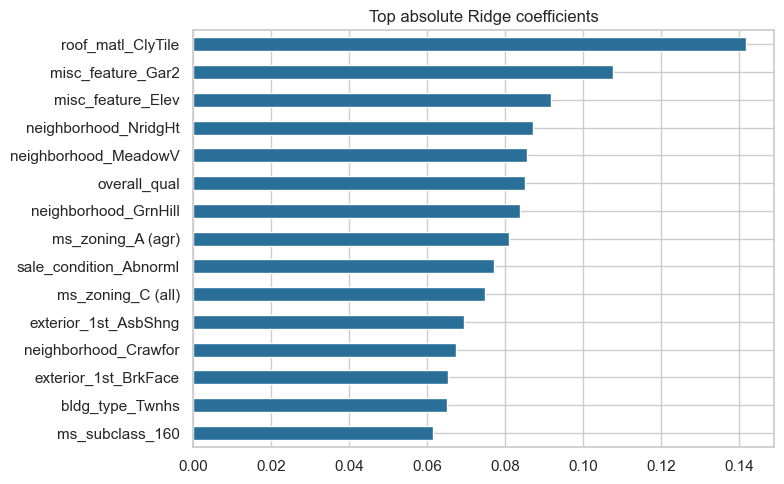

In [19]:
ridge_model = ridge_search.best_estimator_
feature_names = ridge_model.named_steps['preprocess'].get_feature_names_out()
ridge_coef = ridge_model.named_steps['model'].coef_

importance = (
    pd.Series(np.abs(ridge_coef), index=feature_names)
    .sort_values(ascending=False)
    .head(15)
)

print('Top Ridge |coefficients| (log-price scale). Rare categories can look huge, so I treat these as clues, not as a perfect ranking.')
display(importance.to_frame('abs_coefficient'))

importance.sort_values().plot.barh(figsize=(8, 5), color='#2a6f97')
plt.title('Top absolute Ridge coefficients')
plt.tight_layout()
plt.show()


## 10b. Data insights connected to the trained models

The EDA is not a separate story. The same patterns should show up in the fitted SVR/Ridge models.

- **Skew -> log target.** SalePrice skew was about 1.74 and dropped near 0 after `log1p`. That is why a $50k mistake on a cheap house and a $50k mistake on a mansion are handled more fairly in training.
- **Quality and size should dominate.** `overall_qual` (~0.80 corr) and `gr_liv_area` (~0.71 corr) were the strongest numeric plots. If the model is working, predicted price should rise with quality and living area.
- **Location is a real price driver.** Neighborhood boxplots were wide. One-hot encoding lets the model give a bump to areas like NridgHt and a penalty to cheaper areas like MeadowV.
- **`NA` is information.** A missing pool or garage is usually "does not exist". Filling `None` and using ordinal order (`None < Po < Fa < TA < Gd < Ex`) lets the model treat "no basement" as worse than a poor basement.
- **Rare categories can trick Ridge.** Huge Ridge weights on things like `roof_matl_ClyTile` come from a handful of rows, not from a stable housing rule. That is one reason SVR beat Ridge on test even though both looked similar on validation.
- **Why SVR is the final model.** Validation RMSE was slightly better for SVR, and test RMSE stayed better too (~29k vs ~34k). The remaining SVR train/validation gap is the cost of a flexible kernel on a market with expensive outliers.


Selected model: SVR

Mean actual vs predicted price by overall quality (validation):


,actual_price,pred_price
overall_qual,,
2,60000.0,62187.0
3,73986.0,77918.0
4,98752.0,103246.0
5,134571.0,136759.0
6,159100.0,160039.0
7,207494.0,207416.0
8,281903.0,281384.0
9,382860.0,378768.0
10,488201.0,455951.0


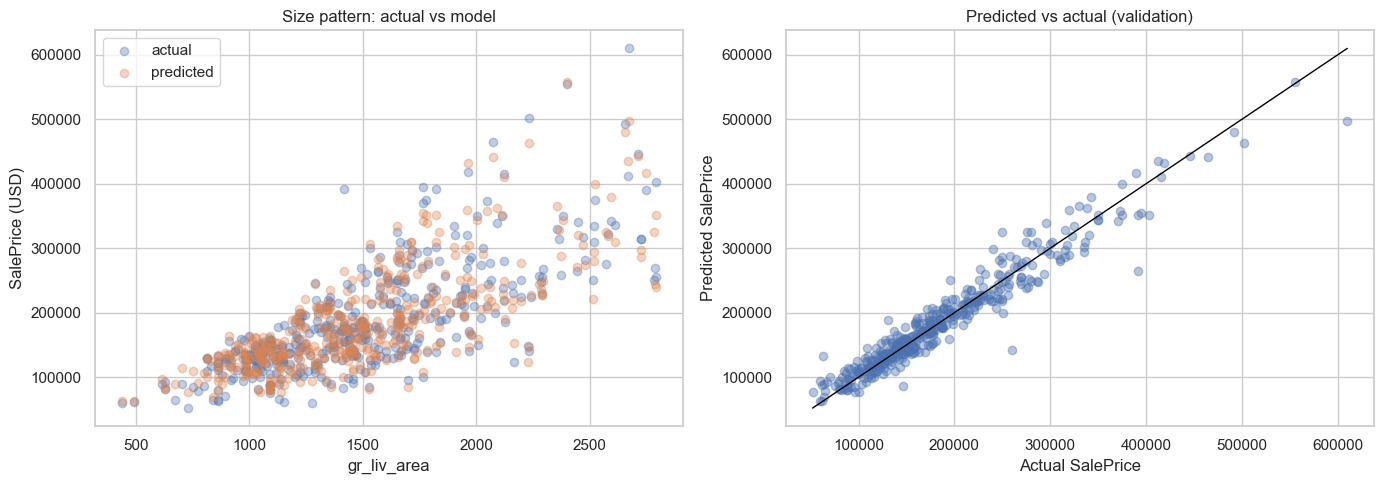

Neighborhoods with the highest mean predicted price:


,mean_predicted_price
neighborhood,
StoneBr,332745.0
NridgHt,326774.0
NoRidge,294826.0
Somerst,231817.0
Blmngtn,228088.0
Timber,227476.0
Veenker,223593.0
Crawfor,216246.0



Where the largest mistakes happen (validation):


,mean_abs_error
neighborhood,
StoneBr,40127.0
Blmngtn,29958.0
Timber,22637.0
NoRidge,21888.0
NridgHt,20509.0
Sawyer,20358.0
ClearCr,18357.0
Crawfor,17897.0



Quick read:
- If predicted price rises with overall_qual, the model learned the quality pattern from EDA.
- Points far from the diagonal are the hard houses: unusual size, rare materials, or very high prices.
- Bigger errors in a few neighborhoods mean location still has leftover price variation the features did not fully capture.


In [20]:
# Check that the main EDA drivers still show up in the selected model
best_model = svr_search.best_estimator_ if final_model_name == 'SVR' else ridge_search.best_estimator_

# validation houses in original dollars
valid_actual = np.expm1(y_valid)
valid_pred = np.maximum(0, np.expm1(best_model.predict(X_valid)))

check = X_valid.copy()
check['actual_price'] = valid_actual
check['pred_price'] = valid_pred
check['abs_error'] = (check['actual_price'] - check['pred_price']).abs()

print('Selected model:', final_model_name)
print()

# 1) quality: both actual and predicted price should rise together
print('Mean actual vs predicted price by overall quality (validation):')
by_qual = (
    check.groupby('overall_qual')[['actual_price', 'pred_price']]
    .mean()
    .round(0)
)
display(by_qual)

# 2) size: living area vs price, with model predictions on top
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(check['gr_liv_area'], check['actual_price'], alpha=0.35, label='actual')
axes[0].scatter(check['gr_liv_area'], check['pred_price'], alpha=0.35, label='predicted')
axes[0].set_xlabel('gr_liv_area')
axes[0].set_ylabel('SalePrice (USD)')
axes[0].set_title('Size pattern: actual vs model')
axes[0].legend()

axes[1].scatter(check['actual_price'], check['pred_price'], alpha=0.4)
lims = [check[['actual_price', 'pred_price']].min().min(), check[['actual_price', 'pred_price']].max().max()]
axes[1].plot(lims, lims, color='black', linewidth=1)
axes[1].set_xlabel('Actual SalePrice')
axes[1].set_ylabel('Predicted SalePrice')
axes[1].set_title('Predicted vs actual (validation)')
plt.tight_layout()
plt.show()

# 3) location: neighborhoods the model finds expensive/cheap
print('Neighborhoods with the highest mean predicted price:')
display(
    check.groupby('neighborhood')['pred_price']
    .mean()
    .sort_values(ascending=False)
    .head(8)
    .round(0)
    .to_frame('mean_predicted_price')
)

print()
print('Where the largest mistakes happen (validation):')
display(
    check.groupby('neighborhood')['abs_error']
    .mean()
    .sort_values(ascending=False)
    .head(8)
    .round(0)
    .to_frame('mean_abs_error')
)

print()
print('Quick read:')
print('- If predicted price rises with overall_qual, the model learned the quality pattern from EDA.')
print('- Points far from the diagonal are the hard houses: unusual size, rare materials, or very high prices.')
print('- Bigger errors in a few neighborhoods mean location still has leftover price variation the features did not fully capture.')


## 11. Export the short PDF report


In [21]:
from matplotlib.backends.backend_pdf import PdfPages

selected_row = results_df.query("model == @final_model_name and split == 'Test'").iloc[0]

report_text = f'''Ames Housing Price Prediction

Dataset: {len(df):,} houses, {df.shape[1] - 1} predictors after IDs were dropped.
Target: SalePrice. Models were trained on log1p(SalePrice) and scored in USD.

Preprocessing
- Numeric: median impute + StandardScaler (needed for SVR/Ridge).
- Nominal: None-fill + One-Hot Encoding.
- Ordinal: None-fill + ordered Ordinal Encoding.
- All of this sits inside ColumnTransformer pipelines (no leakage).
- Extra features: house_age, remod_age, total_sf.

Tuning
- SVR grid (reduced): C, kernel, gamma, degree.
- Ridge grid: alpha.
- Best SVR: {svr_search.best_params_}
- Best Ridge: {ridge_search.best_params_}

Metrics (USD)
{results_df.round(1).to_string(index=False)}

Recommendation
I select {final_model_name} using validation RMSE.
Test MAE={selected_row['MAE']:.0f}, RMSE={selected_row['RMSE']:.0f}, R2={selected_row['R2']:.3f}.
SVR usually fits training data more tightly. If its valid/test gap is large, it is overfitting.
Ridge is more stable and easier to explain through coefficients.

EDA linked to the model
SalePrice is right-skewed, so training used log1p. Quality, living area,
and neighborhood drive both the plots and the predictions. Rare categories
can inflate Ridge weights; SVR handled unseen houses better on test.
'''

with PdfPages('ames_housing_final_report.pdf') as pdf:
    fig = plt.figure(figsize=(8.27, 11.69))
    plt.axis('off')
    fig.text(0.08, 0.96, report_text, va='top', ha='left', fontsize=8.5, family='DejaVu Sans')
    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(8.27, 5.2))
    sns.scatterplot(data=df, x='gr_liv_area', y=target, alpha=0.3, ax=axes[0])
    axes[0].set_title('Living area vs SalePrice')
    sns.boxplot(data=df, x='overall_qual', y=target, ax=axes[1])
    axes[1].set_title('Overall quality vs SalePrice')
    plt.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

print('Saved ames_housing_final_report.pdf')
print('Selected model:', final_model_name)


Saved ames_housing_final_report.pdf
Selected model: SVR
